In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [3]:
# crosstab
pd.crosstab(df["category"], df["isBestSeller"])

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [4]:
# normalize (row-wise)
crosstab = pd.crosstab(df["category"], df["isBestSeller"], normalize="index")

crosstab

isBestSeller,False,True
category,,
3D Printers,0.995968,0.004032
3D Printing & Scanning,0.999508,0.000492
Abrasive & Finishing Products,0.980000,0.020000
Action Cameras,0.999411,0.000589
Adapters,0.988189,0.011811
...,...,...
Wind Instruments,0.972000,0.028000
Window Treatments,0.979079,0.020921
Women,0.988015,0.011985


In [5]:
# sort by bestseller rate
crosstab.sort_values(by=True, ascending=False)

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
...,...,...
Bedding Collections,1.000000,0.000000
CPUs,1.000000,0.000000
"CD, Disc & Tape Players",1.000000,0.000000


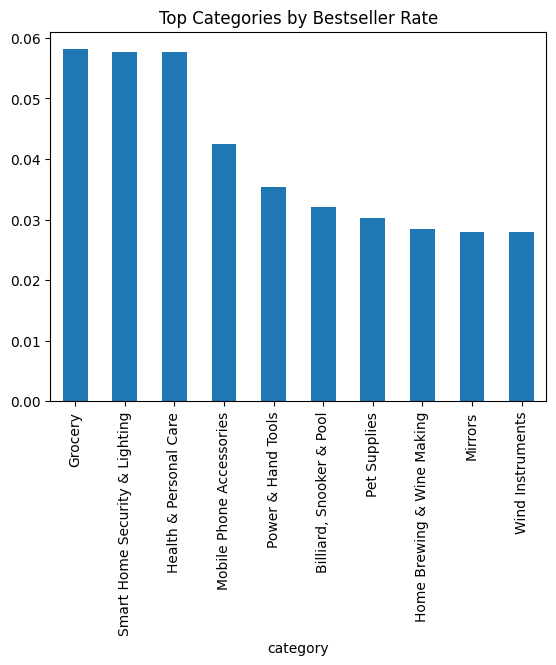

In [6]:
# bar plot
crosstab.sort_values(by=True, ascending=False).head(10)[True].plot(kind="bar")
plt.title("Top Categories by Bestseller Rate")
plt.show()

While some categories have a slightly higher likelihood of producing best-sellers, the differences are relatively small, suggesting that bestseller status is not strongly driven by category alone.

In [8]:
!pip install scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.7/22.7 MB 11.8 MB/s  0:00:01m0:00:0100:01


In [9]:
from scipy.stats import chi2_contingency

In [10]:
# chi-square test
chi2, p, dof, expected = chi2_contingency(pd.crosstab(df["category"], df["isBestSeller"]))

p

np.float64(0.0)

* The Chi-square test shows a statistically significant relationship between product category and bestseller status (p < 0.05).
* Although the relationship is statistically significant, the differences in bestseller rates across categories are relatively small, suggesting that category alone is not a strong driver of bestseller success.

In [11]:
# IQR
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

Q1, Q3, IQR

(np.float64(9.99), np.float64(45.99), np.float64(36.0))

In [12]:
# define bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

lower_bound, upper_bound

(np.float64(-44.01), np.float64(99.99000000000001))

In [13]:
# filter dataset
df_price_clean = df[(df["price"] >= lower_bound) & (df["price"] <= upper_bound)]

In [14]:
# top 10 categories
top_categories = df["category"].value_counts().head(10).index

df_top = df_price_clean[df_price_clean["category"].isin(top_categories)]

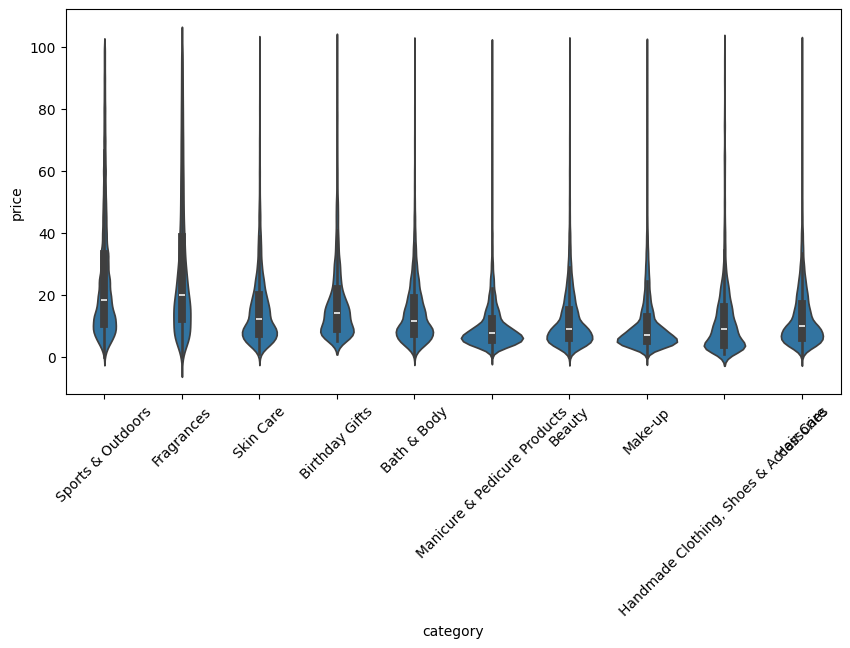

In [15]:
import seaborn as sns

# violin plot
plt.figure(figsize=(10,5))
sns.violinplot(data=df_top, x="category", y="price")
plt.xticks(rotation=45)
plt.show()

In [16]:
# average price per category
avg_price = df_price_clean.groupby("category")["price"].mean().sort_values(ascending=False)

avg_price.head(10)

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

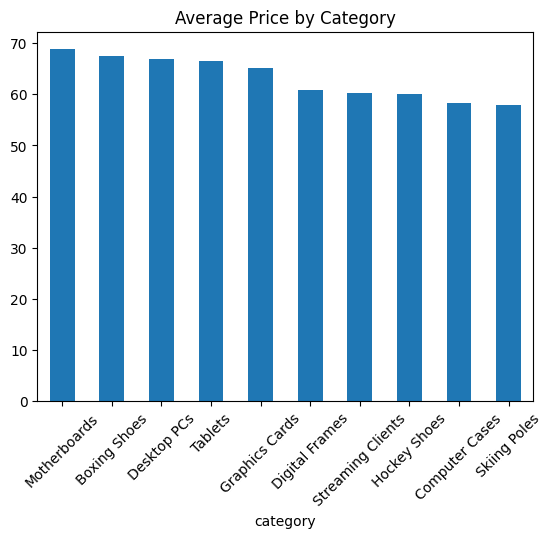

In [17]:
avg_price.head(10).plot(kind="bar")
plt.title("Average Price by Category")
plt.xticks(rotation=45)
plt.show()

Higher-priced categories tend to be technology-related products, suggesting that product type (e.g., electronics) influences pricing more than category labels alone.

In [18]:
# top categories again
top_categories = df["category"].value_counts().head(10).index

df_top = df[df["category"].isin(top_categories)]

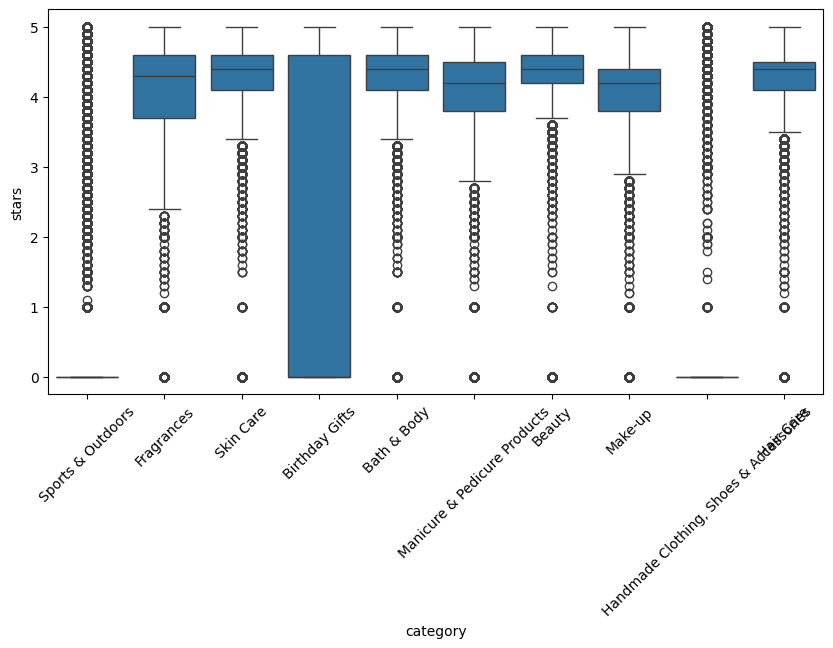

In [19]:
# boxplot ratings
plt.figure(figsize=(10,5))
sns.boxplot(data=df_top, x="category", y="stars")
plt.xticks(rotation=45)
plt.show()


Customer satisfaction appears to be consistently high across product categories, suggesting that category alone does not strongly influence product ratings.

In [20]:
# correlation
df["price"].corr(df["stars"])

np.float64(-0.12490673262148669)

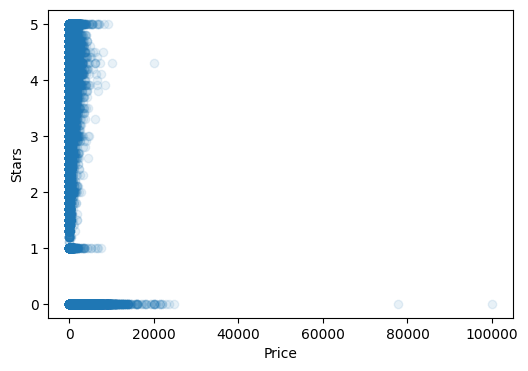

In [21]:
# scatter plot
plt.figure(figsize=(6,4))
plt.scatter(df["price"], df["stars"], alpha=0.1)
plt.xlabel("Price")
plt.ylabel("Stars")
plt.show()

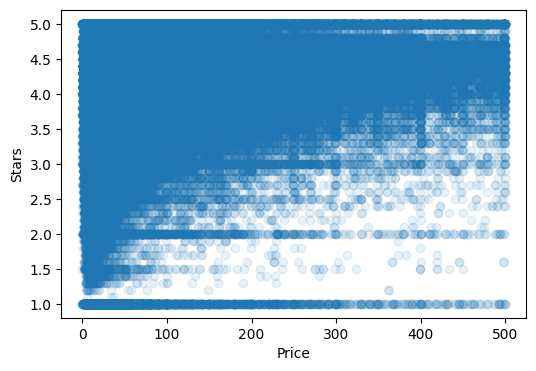

In [22]:
df_clean = df[(df["price"] < 500) & (df["stars"] > 0)]

plt.figure(figsize=(6,4))
plt.scatter(df_clean["price"], df_clean["stars"], alpha=0.1)
plt.xlabel("Price")
plt.ylabel("Stars")
plt.show()

* Correlation between price and rating is very weak (-0.12)
* Scatter plot shows no clear relationship

* Product price does not appear to strongly influence customer ratings. High-rated products exist across all price ranges, suggesting that factors other than price (e.g., product quality or brand) drive customer satisfaction.

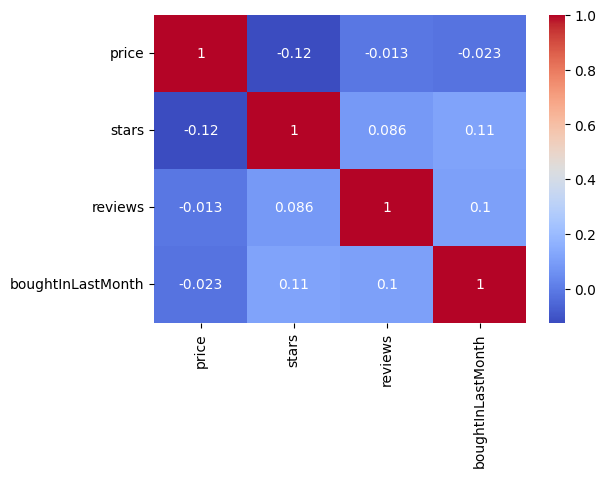

In [23]:
import seaborn as sns

# select numeric columns
corr = df[["price", "stars", "reviews", "boughtInLastMonth"]].corr()

# plot
plt.figure(figsize=(6,4))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()

The heatmap confirms that correlations between variables are generally weak, indicating no strong linear relationships.